# Automated PCB Defect Detection Using Classical Image Processing Techniques

**Course:** ARTI 403 – Image Processing

**Group:** 2

**Team Members:**
- Sara Abdulaziz
- Sarah Khalid
- Dina Moteb
- Raghad Mohammed
- Hawra Habib
- Danah Eid

**Module:** Detection and Bounding Boxes

**Implemented by:** Sarah Khalid

This notebook demonstrates contour-based defect detection, bounding box extraction, and preliminary testing using synthetic and DeepPCB images.

## 1. Contour Detection on a Synthetic Mask

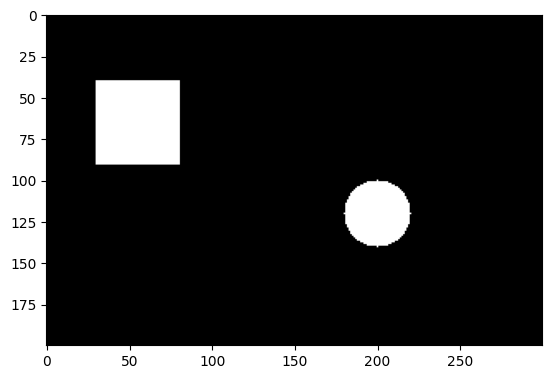

In [68]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

mask = np.zeros((200, 300), dtype=np.uint8)

cv2.rectangle(mask, (30, 40), (80, 90), 255, -1)
cv2.circle(mask, (200, 120), 20, 255, -1)

plt.imshow(mask, cmap="gray")
plt.show()

In [69]:
contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours:", len(contours))

Number of contours: 2


In [70]:
boxes = []
min_area = 100

for contour in contours:
    area = cv2.contourArea(contour)

    if area >= min_area:
        x, y, w, h = cv2.boundingRect(contour)
        boxes.append((x, y, x + w, y + h))

print("Detected boxes:", boxes)

Detected boxes: [(180, 100, 221, 141), (30, 40, 81, 91)]


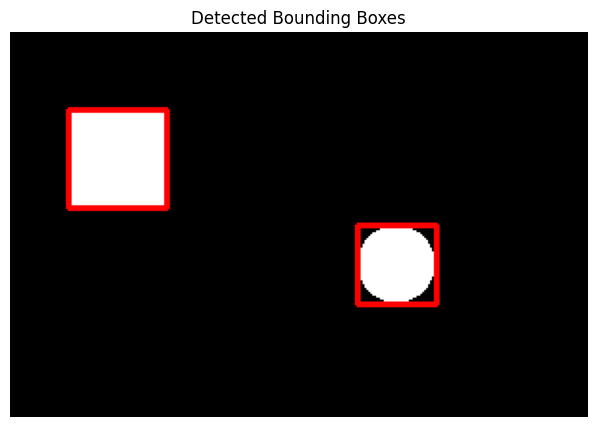

In [71]:
result = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)

for x1, y1, x2, y2 in boxes:
    cv2.rectangle(
        result,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Bounding Boxes")
plt.axis("off")
plt.show()

## 2. Bounding Box Detection Function

In [72]:
def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes

In [73]:
detected_boxes = find_boxes(mask, min_area=100)

print("Number of boxes:", len(detected_boxes))
print("Boxes:", detected_boxes)

Number of boxes: 2
Boxes: [(180, 100, 221, 141), (30, 40, 81, 91)]


In [74]:
for area in [100, 1000, 2000, 3000]:
    detected = find_boxes(mask, min_area=area)
    print(f"min_area={area}: {len(detected)} boxes")

min_area=100: 2 boxes
min_area=1000: 2 boxes
min_area=2000: 1 boxes
min_area=3000: 0 boxes


## 3. Thresholding and Detection on DeepPCB

The binary mask is generated using the thresholding function developed by Danah Eid.

In [75]:
import os
import cv2
import numpy as np

# default settings, the experiments part changes them
THRESH = 50
BLOCK = 31
C = -25
KERNEL = 3


# diff = grayscale difference image (uint8)
# returns a mask of 0 and 255
def make_mask(diff, method="otsu", thresh=THRESH, block=BLOCK, c=C, k=KERNEL, morph=True):
    if method == "fixed":
        _, mask = cv2.threshold(diff, thresh, 255, cv2.THRESH_BINARY)
    elif method == "otsu":
        _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == "adaptive":
        # c is negative because the diff image is mostly black
        mask = cv2.adaptiveThreshold(diff, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, block, c)
    else:
        raise ValueError("method must be fixed, otsu or adaptive")

    if morph and k > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        # opening removes small white dots, closing fills small holes
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask

In [76]:
# Test
diff = mask.copy()

binary = make_mask(diff, method="otsu")
boxes = find_boxes(binary, min_area=100)

print("Number of boxes:", len(boxes))
print("Detected boxes:", boxes)

Number of boxes: 2
Detected boxes: [(181, 101, 220, 140), (30, 40, 81, 91)]


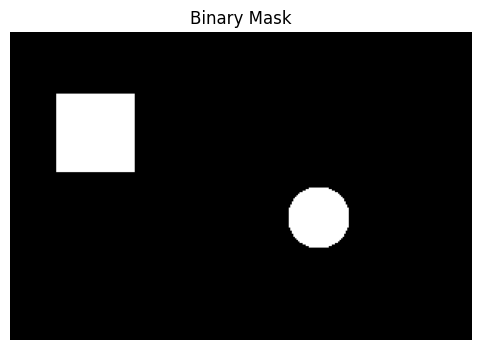

In [77]:
plt.figure(figsize=(7, 4))
plt.imshow(binary, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")
plt.show()

In [78]:
# Download DeepPCB only if it is not already available
!test -d DeepPCB/PCBData || git clone https://github.com/tangsanli5201/DeepPCB.git

In [79]:
from preprocess import difference

In [80]:
# Load the PCB test and template images
test = cv2.imread(
    "DeepPCB/PCBData/group00041/00041/00041000_test.jpg"
)

temp = cv2.imread(
    "DeepPCB/PCBData/group00041/00041/00041000_temp.jpg"
)

if test is None or temp is None:
    raise FileNotFoundError("PCB images could not be loaded")

print("Test image:", test.shape)
print("Template image:", temp.shape)

Test image: (640, 640, 3)
Template image: (640, 640, 3)


In [81]:
# Process the PCB image pair
pcb_diff = difference(test, temp, blur="median", k=5)

# Create a binary mask
pcb_binary = make_mask(pcb_diff, method="otsu")

# Detect possible defects
pcb_boxes = find_boxes(pcb_binary, min_area=100)

print("Test shape:", test.shape)
print("Binary shape:", pcb_binary.shape)
print("Number of boxes:", len(pcb_boxes))
print("Boxes:", pcb_boxes)

Test shape: (640, 640, 3)
Binary shape: (640, 640)
Number of boxes: 3
Boxes: [(100, 479, 117, 487), (467, 317, 484, 382), (551, 271, 583, 304)]


In [82]:
# Test the updated function
test_boxes = find_boxes(pcb_binary, min_area=150, pad=0)

print("Number of boxes:", len(test_boxes))
print("Boxes:", test_boxes)

Number of boxes: 2
Boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]


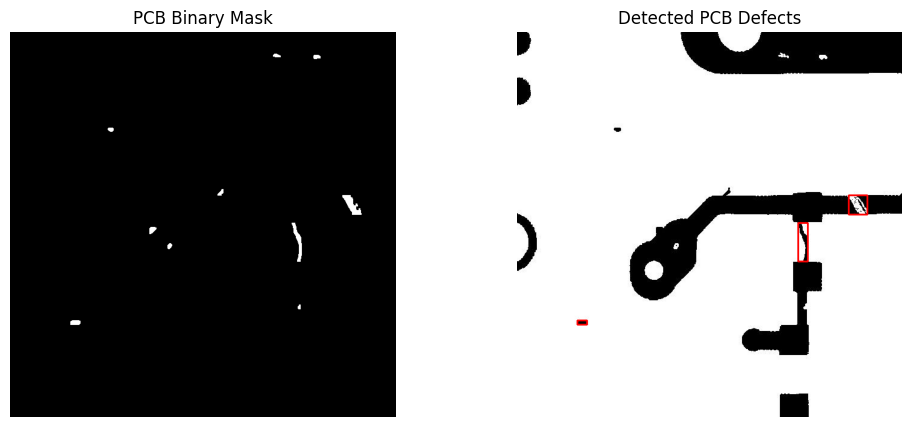

In [83]:
# Draw the detected boxes on the PCB image
pcb_result = test.copy()

for x1, y1, x2, y2 in pcb_boxes:
    cv2.rectangle(
        pcb_result,
        (x1, y1),
        (x2 - 1, y2 - 1),
        (0, 0, 255),
        2
    )

# Display the binary mask and detection results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(pcb_binary, cmap="gray")
plt.title("PCB Binary Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(pcb_result, cv2.COLOR_BGR2RGB))
plt.title("Detected PCB Defects")
plt.axis("off")

plt.show()

## 4. Ground Truth and IoU Comparison

In [84]:
# Load the ground truth annotations
annotation_path = "DeepPCB/PCBData/group00041/00041_not/00041000.txt"

gt_boxes = []

with open(annotation_path, "r") as file:
    for line in file:
        x1, y1, x2, y2, defect_type = map(int, line.split())

        if defect_type in [1, 2]:
            gt_boxes.append((x1, y1, x2, y2, defect_type))

print("Ground Truth:", gt_boxes)

Ground Truth: [(454, 300, 493, 396, 2), (539, 259, 592, 316, 1)]


In [85]:
# Draw ground truth boxes
gt_result = test.copy()

for x1, y1, x2, y2, defect_type in gt_boxes:
    cv2.rectangle(
        gt_result,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

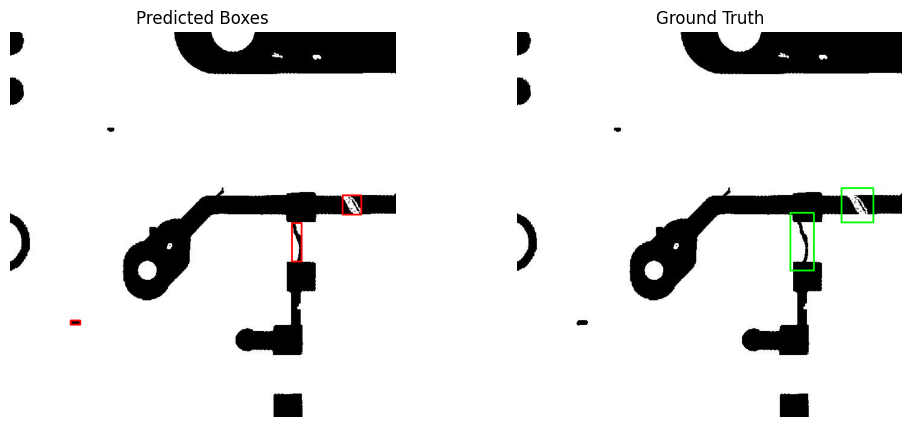

In [86]:
# Compare detected boxes with ground truth
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(pcb_result, cv2.COLOR_BGR2RGB))
plt.title("Predicted Boxes")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(gt_result, cv2.COLOR_BGR2RGB))
plt.title("Ground Truth")
plt.axis("off")

plt.show()

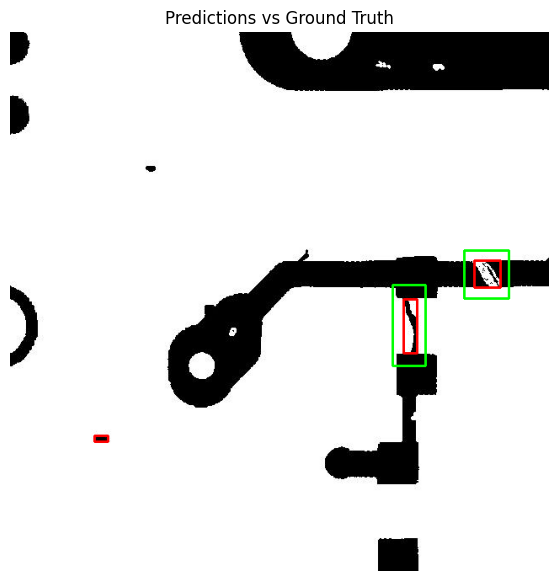

In [87]:
# Compare predictions and ground truth
comparison = test.copy()

# Predicted boxes in red
for x1, y1, x2, y2 in pcb_boxes:
    cv2.rectangle(comparison, (x1, y1), (x2-1, y2-1),
                  (0, 0, 255), 2)

# Ground truth boxes in green
for x1, y1, x2, y2, defect_type in gt_boxes:
    cv2.rectangle(comparison, (x1, y1), (x2, y2),
                  (0, 255, 0), 2)

plt.figure(figsize=(8, 7))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.title("Predictions vs Ground Truth")
plt.axis("off")
plt.show()

In [88]:
# Calculate overlap between two boxes
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [89]:
# Check IoU for each detected box
for i, pred in enumerate(pcb_boxes, start=1):
    scores = [
        calculate_iou(pred, gt[:4])
        for gt in gt_boxes
    ]

    best_iou = max(scores, default=0)

    print(f"Box {i}: Best IoU = {best_iou:.3f}")

Box 1: Best IoU = 0.000
Box 2: Best IoU = 0.295
Box 3: Best IoU = 0.350


## 5. Minimum Area Experiments

The minimum contour area is tested using different values. These results are preliminary and are not used to select the final parameter.

In [90]:
# Check contour areas
contours, _ = cv2.findContours(
    pcb_binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

for contour in contours:
    area = cv2.contourArea(contour)

    if area >= 100:
        x, y, w, h = cv2.boundingRect(contour)
        print("Area:", area, "Box:", (x, y, x+w, y+h))

Area: 105.5 Box: (100, 479, 117, 487)
Area: 322.0 Box: (467, 317, 484, 382)
Area: 420.5 Box: (551, 271, 583, 304)


In [91]:
# Compare different minimum areas
for area in [100, 150, 200, 300]:
    new_boxes = find_boxes(pcb_binary, min_area=area)

    print(f"min_area={area}: {len(new_boxes)} boxes")

min_area=100: 3 boxes
min_area=150: 2 boxes
min_area=200: 2 boxes
min_area=300: 2 boxes


In [92]:
# Compare detected boxes with the ground truth
for area in [100, 150, 200, 300]:
    new_boxes = find_boxes(pcb_binary, min_area=area)

    print(f"\nmin_area = {area}")

    for i, pred in enumerate(new_boxes, start=1):
        scores = [
            calculate_iou(pred, gt[:4])
            for gt in gt_boxes
        ]

        print(f"Box {i}: IoU = {max(scores, default=0):.3f}")


min_area = 100
Box 1: IoU = 0.000
Box 2: IoU = 0.295
Box 3: IoU = 0.350

min_area = 150
Box 1: IoU = 0.295
Box 2: IoU = 0.350

min_area = 200
Box 1: IoU = 0.295
Box 2: IoU = 0.350

min_area = 300
Box 1: IoU = 0.295
Box 2: IoU = 0.350


## 6. Exporting the Detection Module

In [93]:
%%writefile detection.py
import cv2

def find_boxes(binary, min_area=100, pad=0):
    # Find contours in the binary image
    contours, _ = cv2.findContours(
        binary.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []
    height, width = binary.shape[:2]

    for contour in contours:
        # Ignore small regions
        area = cv2.contourArea(contour)

        if area >= min_area:
            # Get bounding box coordinates
            x, y, w, h = cv2.boundingRect(contour)

            # Add padding without exceeding image boundaries
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(width, x + w + pad)
            y2 = min(height, y + h + pad)

            boxes.append((x1, y1, x2, y2))

    return boxes

Overwriting detection.py


In [94]:
from detection import find_boxes

detected = find_boxes(pcb_binary, min_area=150, pad=0)

print("Number of boxes:", len(detected))
print("Detected boxes:", detected)

Number of boxes: 2
Detected boxes: [(467, 317, 484, 382), (551, 271, 583, 304)]
